# Google Playstore Case Study

In this module you’ll be learning data visualisation with the help of a case study. This will enable you to understand how visualisation aids you in solving business problems.

**Problem Statement**

The team at Google Play Store wants to develop a feature that would enable them to boost visibility for the most promising apps. Now, this analysis would require a preliminary understanding of the features that define a well-performing app. You can ask questions like:
- Does a higher size or price necessarily mean that an app would perform better than the other apps?
- Or does a higher number of installs give a clear picture of which app would have a better rating than others?




### Session 1 - Introduction to Data Visualisation

In [ ]:
#import the libraries
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#read the dataset and check the first five rows
inp0 = pd.read_csv('/content/googleplaystore_v2.csv')

inp0.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19000.0,"10,000+",Free,0,Everyone,Art & Design,7-Jan-18,1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14000.0,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,15-Jan-18,2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8700.0,"5,000,000+",Free,0,Everyone,Art & Design,1-Aug-18,1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25000.0,"50,000,000+",Free,0,Teen,Art & Design,8-Jun-18,Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2800.0,"100,000+",Free,0,Everyone,Art & Design;Creativity,20-Jun-18,1.1,4.4 and up


In [ ]:
inp0

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19000.00000,"10,000+",Free,0,Everyone,Art & Design,7-Jan-18,1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14000.00000,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,15-Jan-18,2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8700.00000,"5,000,000+",Free,0,Everyone,Art & Design,1-Aug-18,1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25000.00000,"50,000,000+",Free,0,Teen,Art & Design,8-Jun-18,Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2800.00000,"100,000+",Free,0,Everyone,Art & Design;Creativity,20-Jun-18,1.1,4.4 and up
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10836,Sya9a Maroc - FR,FAMILY,4.5,38,53000.00000,"5,000+",Free,0,Everyone,Education,25-Jul-17,1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3600.00000,100+,Free,0,Everyone,Education,6-Jul-18,1,4.1 and up
10838,Parkinson Exercices FR,MEDICAL,NaN,3,9500.00000,"1,000+",Free,0,Everyone,Medical,20-Jan-17,1,2.2 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,21516.52952,"1,000+",Free,0,Mature 17+,Books & Reference,19-Jan-15,Varies with device,Varies with device


In [ ]:
#Check the shape of the dataframe
print(inp0.shape)

(10841, 13)


### Data Handling and Cleaning

The first few steps involve making sure that there are no __missing values__ or __incorrect data types__ before we proceed to the analysis stage. These aforementioned problems are handled as follows:

 - For Missing Values: Some common techniques to treat this issue are
    - Dropping the rows containing the missing values
    - Imputing the missing values
    - Keep the missing values if they don't affect the analysis

    
 - Incorrect Data Types:
    - Clean certain values
    - Clean and convert an entire column


In [ ]:
#Check the datatypes of all the columns of the dataframe
inp0.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  float64
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(2), object(11)
memory usage: 1.1+ MB


#### Missing Value Treatment

In [ ]:
#Check the number of null values in the columns
inp0.isnull().sum()

,0
App,0
Category,0
Rating,1474
Reviews,0
Size,0
Installs,0
Type,1
Price,0
Content Rating,1
Genres,0


In [ ]:
def missing_values_table(df):


    # Total missing values
    mis_val = df.isna().sum()

    # Percentage of missing values
    mis_val_percentage = 100 * df.isna().sum() / len(df)

    # Combine into a table
    mis_value_table = pd.concat([mis_val, mis_val_percentage], axis=1)

    # Rename the table columns
    mis_value_table.columns = ['Missing Values', '% Missing']

    # Sort the table by missing values
    sorted_missing_values_table = mis_value_table.sort_values(by='Missing Values', ascending=False)

    # Print summary information
    print(f"Your selected data frame has {df.shape[0]} rows and {df.shape[1]} columns.")

    return sorted_missing_values_table

In [ ]:
missing_values_table(inp0)

Your selected data frame has 10841 rows and 13 columns.


,Missing Values,% Missing
Rating,1474,13.596532
Current Ver,8,0.073794
Android Ver,3,0.027673
Content Rating,1,0.009224
Type,1,0.009224
Size,0,0.000000
Reviews,0,0.000000
Category,0,0.000000
App,0,0.000000
Price,0,0.000000


Handling missing values for rating
 - Ratings is the target variable
 - drop the records

In [ ]:
#Drop the rows having null values in the Rating field

inp1 = inp0[~inp0['Rating'].isna()]               # that ~ will make sure to create a new dataframe containing all of the non-null values relative to Rating
# inp0 = inp0.drop(inp0[inp0['Rating'].isna()])

#Check the shape of the dataframe
print(inp1.shape)

(9367, 13)


In [ ]:
# Check the number of nulls in the Rating field again to cross-verify
inp1[inp1['Rating'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver


In [ ]:
#Question
#Check the number of nulls in the dataframe again and find the total number of null values

inp1.isnull().sum()

,0
App,0
Category,0
Rating,0
Reviews,0
Size,0
Installs,0
Type,0
Price,0
Content Rating,1
Genres,0


In [ ]:
#Inspect the nulls in the Android Version column
inp1[inp1['Android Ver'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
4453,[substratum] Vacuum: P,PERSONALIZATION,4.4,230,11000.00000,"1,000+",Paid,$1.49,Everyone,Personalization,20-Jul-18,4.4,NaN
4490,Pi Dark [substratum],PERSONALIZATION,4.5,189,2100.00000,"10,000+",Free,0,Everyone,Personalization,27-Mar-18,1.1,NaN
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,21516.52952,Free,0,Everyone,NaN,11-Feb-18,1.0.19,4.0 and up,NaN


In [ ]:
inp1[inp1['App'] == 'Life Made WI-Fi Touchscreen Photo Frame']

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,21516.52952,Free,0,Everyone,NaN,11-Feb-18,1.0.19,4.0 and up,NaN


In [ ]:
inp1.index[inp1['App'] == 'Life Made WI-Fi Touchscreen Photo Frame']

Index([10472], dtype='int64')

In [ ]:
#Drop the row having shifted values
# inp1 = inp1.drop(inp1[inp1['App'] == 'Life Made WI-Fi Touchscreen Photo Frame'], axis = 1)

inp1 = inp1.drop(10472)
#Check the nulls again in Android version column to cross-verify
inp1[inp1['Android Ver'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
4453,[substratum] Vacuum: P,PERSONALIZATION,4.4,230,11000.0,"1,000+",Paid,$1.49,Everyone,Personalization,20-Jul-18,4.4,NaN
4490,Pi Dark [substratum],PERSONALIZATION,4.5,189,2100.0,"10,000+",Free,0,Everyone,Personalization,27-Mar-18,1.1,NaN


In [ ]:
inp1.iloc[4453]

,4649
App,U get - Wireless Speed Test
Category,TOOLS
Rating,4.2
Reviews,26
Size,2200.0
Installs,"5,000+"
Type,Free
Price,0
Content Rating,Everyone
Genres,Tools


Imputing Missing Values

- For numerical variables use mean and median
- For categorical variables use mode

In [ ]:
#Check the most common value in the Android version column
inp1[['Last Updated', 'Android Ver']].value_counts()

Last Updated  Android Ver       
2-Aug-18      Varies with device    95
31-Jul-18     Varies with device    89
3-Aug-18      Varies with device    87
              4.1 and up            85
1-Aug-18      Varies with device    83
                                    ..
1-Dec-16      2.3 and up             1
1-Apr-17      4.4 and up             1
1-Aug-17      4.0 and up             1
9-Mar-18      7.0 and up             1
9-May-16      4.0.3 and up           1
Name: count, Length: 3716, dtype: int64

In [ ]:
#Fill up the nulls in the Android Version column with the above value
inp1['Android Ver'] = inp1['Android Ver'].fillna('Varies with device')

In [ ]:
#Check the nulls in the Android version column again to cross-verify
inp1[inp1['Android Ver'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver


In [ ]:
#Check the nulls in the entire dataframe again
inp1.isna().sum()

,0
App,0
Category,0
Rating,0
Reviews,0
Size,0
Installs,0
Type,0
Price,0
Content Rating,0
Genres,0


In [ ]:
#Check the most common value in the Current version column
inp1['Current Ver'].mode()

,Current Ver
0,Varies with device


In [ ]:
inp1[inp1['App'] == 'Learn To Draw Kawaii Characters']

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
15,Learn To Draw Kawaii Characters,ART_AND_DESIGN,3.2,55,2700.0,"5,000+",Free,0,Everyone,Art & Design,6-Jun-18,NaN,4.2 and up


In [ ]:
#Replace the nulls in the Current version column with the above value

inp1['Current Ver'] = inp1['Current Ver'].fillna('Varies with device')

In [ ]:
# Question : Check the most common value in the Current version column again
inp1[inp1['Current Ver'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver


#### Handling Incorrect Data Types

In [ ]:
#Check the datatypes of all the columns
inp1.dtypes

,0
App,object
Category,object
Rating,float64
Reviews,object
Size,float64
Installs,object
Type,object
Price,object
Content Rating,object
Genres,object


In [ ]:
inp1.shape

(9366, 13)

In [ ]:
#Question - Try calculating the average price of all apps having the Android version as "4.1 and up"

ver = inp1[inp1['Android Ver'] == '4.1 and up']
# ver['Price'].mean()                 # we typed this code however since it is producing error that strings mean canot be determined and is blocking run all
                                            # commenting out

In [ ]:
#Analyse the Price column to check the issue

inp1['Price'].value_counts()             # value_counts() is used to find the distinct values in a column aand it tells how many there are of those distinct values

,count
Price,
0,8719
$2.99,114
$0.99,107
$4.99,70
$1.99,59
...,...
$2.95,1
$2.90,1
$1.97,1


In [ ]:
#Write the function to make the changes

inp1['Price'] = inp1['Price'].apply(
    lambda x:0 if x == '0' else float(x[1:])         # learn it
)

In [ ]:
#Verify the dtype of Price once again
inp1['Price'].dtype

dtype('float64')

In [ ]:
#Analyse the Reviews column
inp1['Reviews'].value_counts()

,count
Reviews,
2,83
3,78
5,74
4,74
1,67
...,...
9894,1
316378,1
8484,1


In [ ]:
inp1['Reviews'].info()

<class 'pandas.core.series.Series'>
Index: 9366 entries, 0 to 10840
Series name: Reviews
Non-Null Count  Dtype 
--------------  ----- 
9366 non-null   object
dtypes: object(1)
memory usage: 146.3+ KB


In [ ]:
#Change the dtype of this column

inp1['Reviews'] = inp1['Reviews'].astype(int)
#Check the quantitative spread of this dataframe

inp1['Reviews'].dtype

dtype('int64')

In [ ]:
#Analyse the Installs Column

inp1['Installs'].value_counts()

,count
Installs,
"1,000,000+",1577
"10,000,000+",1252
"100,000+",1150
"10,000+",1010
"5,000,000+",752
"1,000+",713
"500,000+",538
"50,000+",467
"5,000+",432


In [ ]:
#Question Clean the Installs Column and find the approximate number of apps at the 50th percentile.
inp1['Installs'] = inp1['Installs'].str.replace(',', '').str.replace('+','')

In [ ]:
inp1['Installs'].value_counts()

,count
Installs,
1000000,1577
10000000,1252
100000,1150
10000,1010
5000000,752
1000,713
500000,538
50000,467
5000,432


In [ ]:
inp1['Installs'] = inp1['Installs'].astype(int)
inp1['Installs'].dtype

dtype('int64')

In [ ]:
inp1['Installs'].describe()

,Installs
count,9.366000e+03
mean,1.789744e+07
std,9.123822e+07
min,1.000000e+00
25%,1.000000e+04
50%,5.000000e+05
75%,5.000000e+06
max,1.000000e+09


#### Sanity Checks

The data that we have needs to make sense and therefore you can perform certain sanity checks on them to ensure they are factually correct as well. Some sanity checks can be:

- Rating is between 1 and 5 for all the apps.
- Number of Reviews is less than or equal to the number of Installs.
- Free Apps shouldn’t have a price greater than 0.


In [ ]:
#Perform the sanity checks on the Reviews column
print(inp1[inp1['Reviews'] > inp1['Installs']])

                                 App   Category  Rating  Reviews         Size  \
2454             KBA-EZ Health Guide    MEDICAL     5.0        4  25000.00000   
4663   Alarmy (Sleep If U Can) - Pro  LIFESTYLE     4.8    10249  21516.52952   
5917                        Ra Ga Ba       GAME     5.0        2  20000.00000   
6700                Brick Breaker BR       GAME     5.0        7  19000.00000   
7402            Trovami se ci riesci       GAME     5.0       11   6100.00000   
8591                         DN Blog     SOCIAL     5.0       20   4200.00000   
10697                        Mu.F.O.       GAME     5.0        2  16000.00000   

       Installs  Type  Price Content Rating     Genres Last Updated  \
2454          1  Free   0.00       Everyone    Medical     2-Aug-18   
4663      10000  Paid   2.49       Everyone  Lifestyle    30-Jul-18   
5917          1  Paid   1.49       Everyone     Arcade     8-Feb-17   
6700          5  Free   0.00       Everyone     Arcade    23-Jul-18

In [ ]:
inp1 = inp1[inp1['Reviews'] <= inp1['Installs']]           # we updated inp1 to not have reviews > installs

In [ ]:
inp1.shape

(9359, 13)

In [ ]:
#perform the sanity checks on prices of free apps
inp1[(inp1['Type'] == 'Free') & (inp1['Price'] > 0)]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver


In [ ]:
inp1.shape

(9359, 13)

In [ ]:
inp1[(inp1['Type'] == 'Paid') & (inp1['Price'] > 0)]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
234,TurboScan: scan documents and receipts in PDF,BUSINESS,4.7,11442,6800.00000,100000,Paid,4.99,Everyone,Business,25-Mar-18,1.5.2,4.0 and up
235,Tiny Scanner Pro: PDF Doc Scan,BUSINESS,4.8,10295,39000.00000,100000,Paid,4.99,Everyone,Business,11-Apr-17,3.4.6,3.0 and up
290,TurboScan: scan documents and receipts in PDF,BUSINESS,4.7,11442,6800.00000,100000,Paid,4.99,Everyone,Business,25-Mar-18,1.5.2,4.0 and up
291,Tiny Scanner Pro: PDF Doc Scan,BUSINESS,4.8,10295,39000.00000,100000,Paid,4.99,Everyone,Business,11-Apr-17,3.4.6,3.0 and up
427,Puffin Browser Pro,COMMUNICATION,4.0,18247,21516.52952,100000,Paid,3.99,Everyone,Communication,5-Jul-18,7.5.3.20547,4.1 and up
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10682,Fruit Ninja Classic,GAME,4.3,85468,36000.00000,1000000,Paid,0.99,Everyone,Arcade,8-Jun-18,2.4.1.485300,4.0.3 and up
10690,FO Bixby,PERSONALIZATION,5.0,5,861.00000,100,Paid,0.99,Everyone,Personalization,25-Apr-18,0.2,7.0 and up
10760,Fast Tract Diet,HEALTH_AND_FITNESS,4.4,35,2400.00000,1000,Paid,7.99,Everyone,Health & Fitness,8-Aug-18,1.9.3,4.2 and up
10782,Trine 2: Complete Story,GAME,3.8,252,11000.00000,10000,Paid,16.99,Teen,Action,27-Feb-15,2.22,5.0 and up


#### Outliers Analysis Using Boxplot

Now you need to start identifying and removing extreme values or __outliers__ from our dataset. These values can tilt our analysis and often provide us with a biased perspective of the data available. This is where you’ll start utilising visualisation to achieve your tasks. And the best visualisation to use here would be the box plot. Boxplots are one of the best ways of analysing the spread of a numeric variable


Using a box plot you can identify the outliers as follows:

![BoxPlots to Identify Outliers](images\Boxplot.png)

- Outliers in data can arise due to genuine reasons or because of dubious entries. In the latter case, you should go ahead and remove such entries immediately. Use a boxplot to observe, analyse and remove them.
- In the former case, you should determine whether or not removing them would add value to your analysis procedure.

- You can create a box plot directly from pandas dataframe or the matplotlib way as you learnt in the previous session. Check out their official documentation here:
   - https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.boxplot.html
   - https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.boxplot.html

In [ ]:
#import the plotting libraries

import matplotlib.pyplot as plt
import seaborn as sns

<Axes: ylabel='Price'>

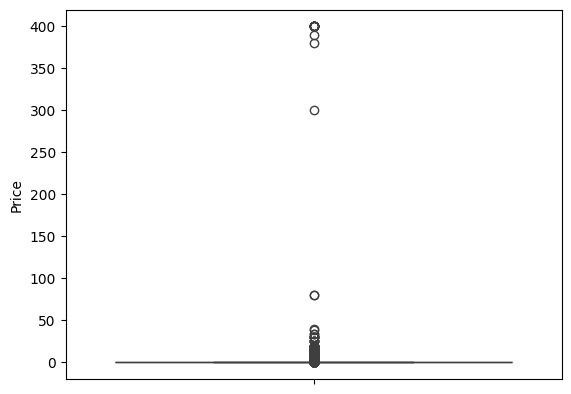

In [ ]:
#Create a box plot for the price column
sns.boxplot(inp1['Price'])

In [ ]:
inp1[inp1['Price'] == 0].shape

(8715, 13)

In [ ]:
inp1[inp1['Price'] != 0].shape

(644, 13)

<Axes: ylabel='Price'>

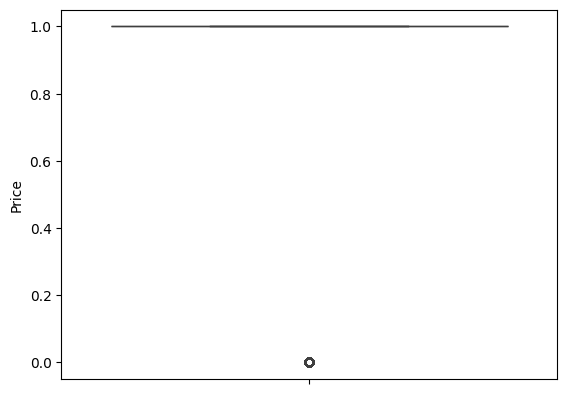

In [ ]:
sns.boxplot(inp1['Price'] == 0)

In [ ]:
paid = inp1[inp1['Price'] > 0]

<Axes: ylabel='Price'>

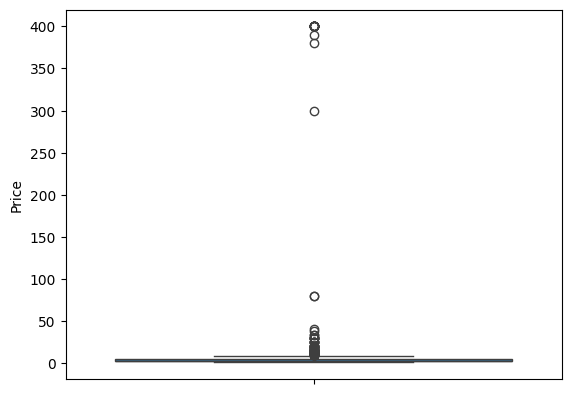

In [ ]:
sns.boxplot(paid['Price'])

In [ ]:
#Check the apps with price more than 250
paid[paid['Price'] > 250]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
4197,most expensive app (H),FAMILY,4.3,6,1500.0,100,Paid,399.99,Everyone,Entertainment,16-Jul-18,1,7.0 and up
4362,💎 I'm rich,LIFESTYLE,3.8,718,26000.0,10000,Paid,399.99,Everyone,Lifestyle,11-Mar-18,1.0.0,4.4 and up
4367,I'm Rich - Trump Edition,LIFESTYLE,3.6,275,7300.0,10000,Paid,400.00,Everyone,Lifestyle,3-May-18,1.0.1,4.1 and up
5351,I am rich,LIFESTYLE,3.8,3547,1800.0,100000,Paid,399.99,Everyone,Lifestyle,12-Jan-18,2,4.0.3 and up
5354,I am Rich Plus,FAMILY,4.0,856,8700.0,10000,Paid,399.99,Everyone,Entertainment,19-May-18,3,4.4 and up
5355,I am rich VIP,LIFESTYLE,3.8,411,2600.0,10000,Paid,299.99,Everyone,Lifestyle,21-Jul-18,1.1.1,4.3 and up
5356,I Am Rich Premium,FINANCE,4.1,1867,4700.0,50000,Paid,399.99,Everyone,Finance,12-Nov-17,1.6,4.0 and up
5357,I am extremely Rich,LIFESTYLE,2.9,41,2900.0,1000,Paid,379.99,Everyone,Lifestyle,1-Jul-18,1,4.0 and up
5358,I am Rich!,FINANCE,3.8,93,22000.0,1000,Paid,399.99,Everyone,Finance,11-Dec-17,1,4.1 and up
5359,I am rich(premium),FINANCE,3.5,472,965.0,5000,Paid,399.99,Everyone,Finance,1-May-17,3.4,4.4 and up


In [ ]:
import plotly.express as px
fig = px.box(paid, y = 'Price')
fig.show()

In [ ]:
#Clean the Price column
inp1 = inp1[inp1['Price'] <= 250]

In [ ]:
inp1.shape

(9344, 13)

<Axes: ylabel='Price'>

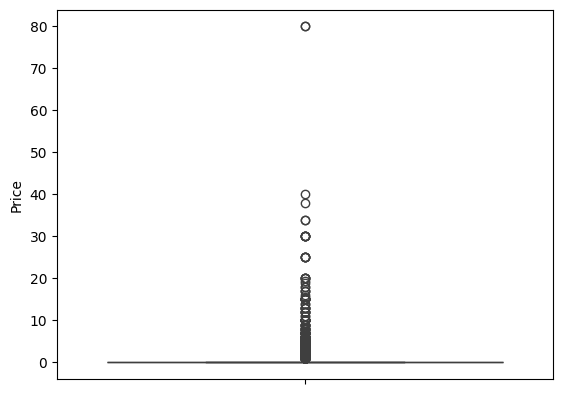

In [ ]:
#Create a box plot for paid apps

sns.boxplot(inp1['Price'])

In [ ]:
#Check the apps with price more than 40

inp1[inp1['Price'] > 40]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
2253,Vargo Anesthesia Mega App,MEDICAL,4.6,92,32000.0,1000,Paid,79.99,Everyone,Medical,18-Jun-18,19,4.0.3 and up
2365,Vargo Anesthesia Mega App,MEDICAL,4.6,92,32000.0,1000,Paid,79.99,Everyone,Medical,18-Jun-18,19,4.0.3 and up


In [ ]:
#Clean the Price column again
inp1 = inp1[inp1['Price'] <= 40]

In [ ]:
inp1.shape

(9342, 13)

### Histograms

Histograms can also be used in conjuction with boxplots for data cleaning and data handling purposes. You can use it to check the spread of a numeric variable. Histograms generally work by bucketing the entire range of values that a particular variable takes to specific __bins__. After that, it uses vertical bars to denote the total number of records in a specific bin, which is also known as its __frequency__.


![Histogram](images\Histogram.png)

You can adjust the number of bins to improve its granularity

![Bins change](images\Granular.png)

You'll be using plt.hist() to plot a histogram. Check out its official documentation:https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.hist.html

In [ ]:
#Create a histogram of the Reviews
import plotly.express as px
fig = px.histogram(inp1, x = 'Reviews')
fig.show()


In [ ]:
import plotly.express as px
fig = px.histogram(inp1, x = np.log1p(inp1['Reviews']),                     # we r transforming into log due to data being too high, so to understand the
                   title = 'Histogram of Log-Transformed Reviews')              # distribution we r using log.
fig.show()

<Axes: xlabel='Reviews', ylabel='Count'>

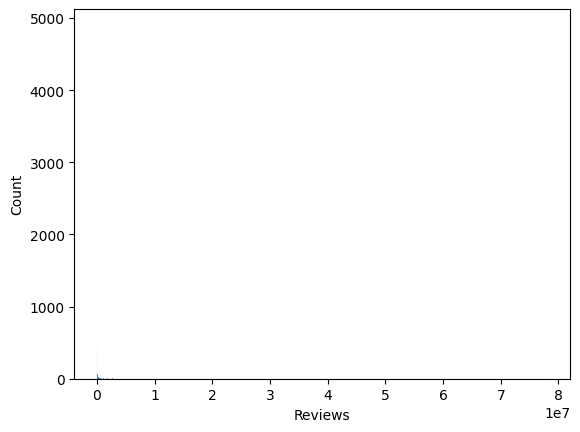

In [ ]:
sns.histplot(data = inp1, x = 'Reviews')

<Axes: xlabel='Reviews', ylabel='Count'>

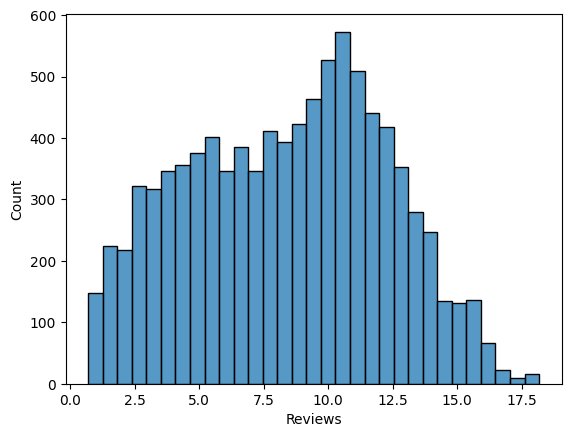

In [ ]:
sns.histplot(data = inp1, x = np.log1p(inp1['Reviews']))    # without log we r getting above graph

<Axes: ylabel='Reviews'>

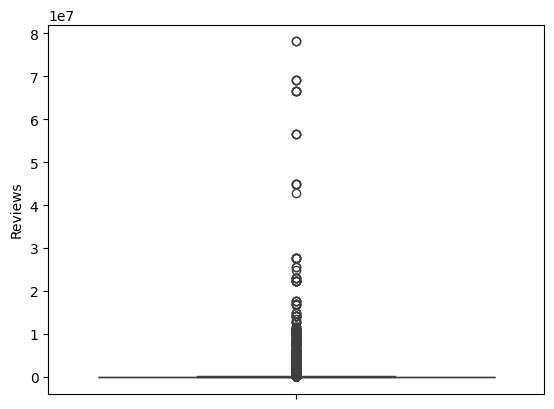

In [ ]:
#Create a boxplot of the Reviews column

sns.boxplot(inp1['Reviews'])

In [ ]:
# Create a boxplot of the Reviews column with a log scale on the y-axis
fig = px.box(inp1, y = 'Reviews', log_y = True, title = 'Boxplot of Reviews (Log Scale)')
fig.show()

In [ ]:
#Check records with 1 million reviews
print(inp1[inp1['Reviews'] > 1000000].shape)
print(inp1[inp1['Reviews'] <= 1000000].shape)

(704, 13)
(8638, 13)


In [ ]:
inp3 = inp1[inp1['Reviews'] > 1000000]

In [ ]:
inp3.shape

(704, 13)

In [ ]:
#Drop the above records
inp1 = inp1[inp1['Reviews'] <= 1000000]
inp1.shape

(8638, 13)

<Axes: xlabel='Reviews', ylabel='Count'>

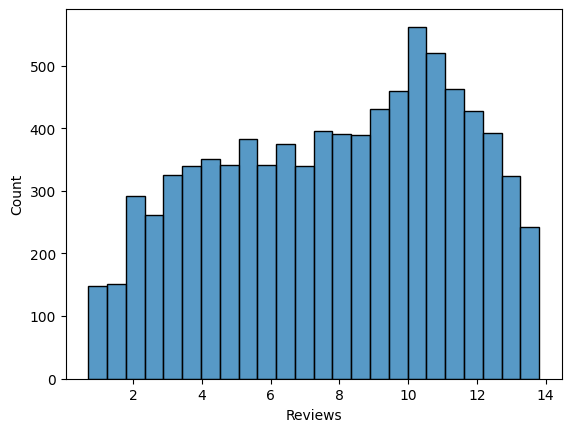

In [ ]:
#Question - Create a histogram again and check the peaks

sns.histplot(data = inp1, x = np.log1p(inp1['Reviews']))

In [ ]:
import plotly.express as px
fig = px.histogram(data_frame = inp1, x = 'Reviews', log_y = True,
title = 'Distribution of Reviews (Log Scale)'
                   )
fig.show()

In [ ]:
import plotly.express as px
fig = px.histogram(data_frame = inp3, x = 'Reviews', log_y = True,
title = 'Distribution of Reviews (Log Scale)'
                   )
fig.show()

In [ ]:
#Question - Create a box plot for the Installs column and report back the IQR


fig = px.box(inp1, y = 'Installs', log_y = True,
title = 'Boxplot of Installs (Log Scale)'
                   )
fig.show()

In [ ]:
#Question - CLean the Installs by removing all the apps having more than or equal to 100 million installs

inp4 = inp1[inp1['Installs'] >= 100000000]

In [ ]:
inp4.shape

(61, 13)

In [ ]:
inp1 = inp1[inp1['Installs'] < 100000000]

In [ ]:
inp1.shape

(8577, 13)

<Axes: xlabel='Size', ylabel='Count'>

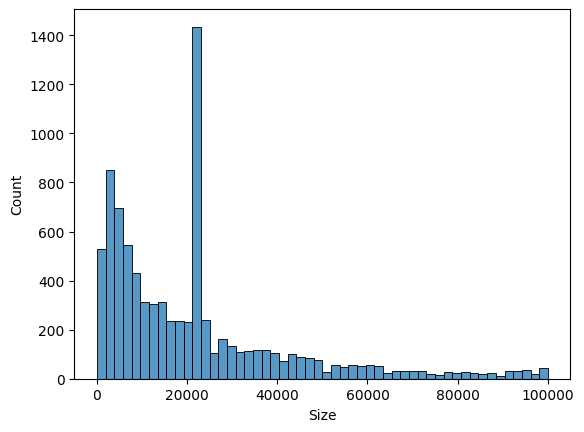

In [ ]:
#Plot a histogram for Size as well.
sns.histplot(data = inp1, x = 'Size')

<Axes: ylabel='Size'>

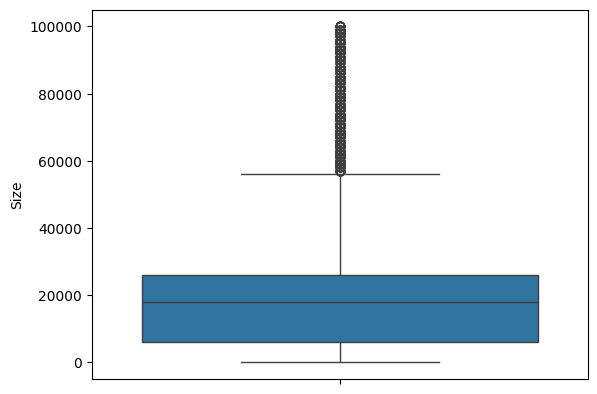

In [ ]:
#Question - Create a boxplot for the Size column and report back the median value
sns.boxplot(inp1['Size'])

In [ ]:
fig = px.box(inp1, y = 'Size',
             title = 'Boxplot of Size Column')
fig.show()

### Session 2 - Data Visualisation with Seaborn

Seaborn is Python library to create statistical graphs easily. It is built on top of matplotlib and closely integrated with pandas.

_Functionalities of Seaborn_ :

- Dataset oriented API
- Analysing univariate and bivariate distributions
- Automatic estimation and plotting of  linear regression models
- Convenient views for complex datasets
- Concise control over style
- Colour palettes


In [ ]:
#import the necessary libraries


#### Distribution Plots

A distribution plot is pretty similar to the histogram functionality in matplotlib. Instead of a frequency plot, it plots an approximate probability density for that rating bucket. And the curve (or the __KDE__) that gets drawn over the distribution is the approximate probability density curve.

The following is an example of a distribution plot. Notice that now instead of frequency on the left axis, it has the density for each bin or bucket.

![Distplot](images\Distplot.png)

You'll be using sns.distplot for plotting a distribution plot. Check out its official documentation: https://seaborn.pydata.org/generated/seaborn.distplot.html

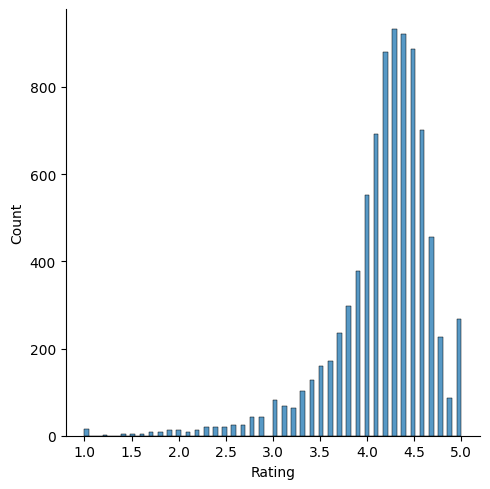

In [ ]:
#Create a distribution plot for rating
sns.displot(data = inp1, x = 'Rating')

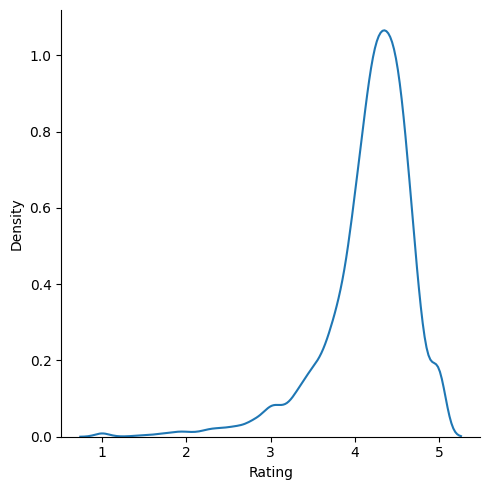

In [ ]:
sns.displot(data = inp1, x = 'Rating', kind = 'kde')

In [ ]:
import plotly.express as px
fig = px.histogram(inp1, x='Rating', nbins=30, title='Distribution of Rating')
fig.show()

In [ ]:
#Change the number of bins

import plotly.express as px
fig = px.histogram(inp1, x='Rating', nbins=100, title='Distribution of Rating')
fig.show()

In [ ]:
#Change the colour of bins to green
fig = px.histogram(inp1, x='Rating', nbins=100, title='Distribution of Rating', color_discrete_sequence = ['green'])
fig.show()

In [ ]:
#Apply matplotlib functionalities

fig = px.histogram(inp1, x='Rating', nbins=100, title='Distribution of Rating', color_discrete_sequence = ['green'])
fig.update_layout(xaxis_title='App Rating')
fig.show()

#### Styling Options

One of the biggest advantages of using Seaborn is that you can retain its aesthetic properties and also the Matplotlib functionalities to perform additional customisations. Before we continue with our case study analysis, let’s study some styling options that are available in Seaborn.

-  Check out the official documentation:https://seaborn.pydata.org/generated/seaborn.set_style.html

In [ ]:
#Check all the styling options

In [ ]:
#Change the number of bins to 20


#### Pie-Chart and Bar Chart

For analysing how a numeric variable changes across several categories of a categorical variable you utilise either a pie chart or a box plot

For example, if you want to visualise the responses of a marketing campaign, you can use the following views:

![PieChart](images\pie.png)

![barChart](images\bar.png)

- You'll be using the pandas method of plotting both a pie chart and a bar chart. Check out their official documentations:
   - https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.plot.bar.html
   - https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.plot.pie.html

In [ ]:
#Analyse the Content Rating column
inp1['Content Rating'].value_counts()

,count
Content Rating,
Everyone,6902
Teen,918
Mature 17+,417
Everyone 10+,336
Adults only 18+,3
Unrated,1


In [ ]:
#Remove the rows with values which are less represented
inp1[inp1['Content Rating'] == 'Unrated']

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
8266,DC Universe Online Map,TOOLS,4.1,1186,6400.0,50000,Free,0.0,Unrated,Tools,27-Feb-12,1.3,2.3.3 and up


In [ ]:
inp1 = inp1.drop(8266)

In [ ]:
inp1[inp1['Content Rating'] == 'Adults only 18+']

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
298,Manga Master - Best manga & comic reader,COMICS,4.6,24005,4900.00000,500000,Free,0.0,Adults only 18+,Comics,4-Jul-18,1.1.7.0,4.1 and up
3043,DraftKings - Daily Fantasy Sports,SPORTS,4.5,50017,41000.00000,1000000,Free,0.0,Adults only 18+,Sports,24-Jul-18,3.21.324,4.4 and up
6424,Manga Books,COMICS,3.8,7326,21516.52952,500000,Free,0.0,Adults only 18+,Comics,3-Aug-18,Varies with device,Varies with device


In [ ]:
inp1 = inp1[~(inp1['Content Rating'] == 'Adults only 18+')]

In [ ]:
inp1[inp1['Content Rating'] == 'Adults only 18+']

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver


In [ ]:
inp1.shape

(8573, 13)

In [ ]:
#Reset the index


In [ ]:
#Check the apps belonging to different categories of Content Rating
inp1['Content Rating'].value_counts()

,count
Content Rating,
Everyone,6902
Teen,918
Mature 17+,417
Everyone 10+,336


In [ ]:
# we can now create a new csv file by below method:
inp1.to_csv('googleplaystore_cleaned.csv', index = False)

# with this whatever data cleaning we have done will be saved in our local storage as an individual file, and now we dont have to clean everything again, THANK GOD!
# however it wont be saved in our folder but side files from where we uploaded above dataset

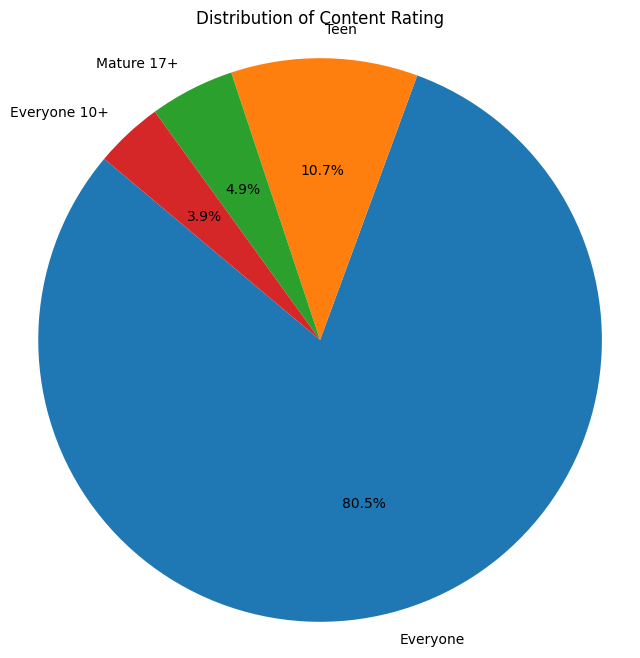

In [ ]:
#Plot a pie chart

content_rating_counts = inp1['Content Rating'].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(content_rating_counts, labels=content_rating_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Distribution of Content Rating')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

In [ ]:
content_rating_counts = inp1['Content Rating'].value_counts()
import plotly.express as px
fig = px.pie(names=content_rating_counts.index, values=content_rating_counts.values, title='Distribution of Content Rating')
fig.show()

In [ ]:
#Plot a bar chart
import plotly.express as px
fig = px.bar(x=content_rating_counts.index, y=content_rating_counts.values, title='Distribution of Content Rating')
fig.update_xaxes(title_text='Content Rating')
fig.update_yaxes(title_text='Count')
fig.show()

In [ ]:
#Plot a bar plot for checking the 4th highest Android version type
android_version_counts = inp1['Android Ver'].value_counts()

# Get the top N versions (e.g., top 5) for better visualization
top_n_android_versions = android_version_counts.head(5)

import plotly.express as px
fig = px.bar(x=top_n_android_versions.index, y=top_n_android_versions.values,
             title='Top 5 Android Version Types',
             labels={'x': 'Android Version', 'y': 'Count'})
fig.update_xaxes(categoryorder='total descending') # Ensure bars are sorted by count
fig.show()

#### Scatter Plots

Scatterplots are perhaps one of the most commonly used as well one of the most powerful visualisations you can use in the field of machine learning. They are pretty crucial in revealing relationships between the data points and you can generally deduce some sort of trends in the data with the help of a scatter plot.

![Scatterplot](images\scatter.png)

- They're pretty useful in regression problems to check whether a linear trend exists in the data or not. For example, in the image below, creating a linear model in the first case makes far more sense since a clear straight line trend is visible.

![Scatterplot-Reg](images\regression3.png)

- Also, they help in observing __naturally occuring clusters__. In the following image, the marks of students in Maths and Biology has been plotted.You can clearly group the students to 4 clusters now. Cluster 1 are students who score very well in Biology but very poorly in Maths, Cluster 2 are students who score equally well in both the subjects and so on.

![Scatter-Clusters](images\Clusters.png)

**Note**: You'll be studying about both Regression and Clustering in greater detail in the machine learning modules

You'll be using **sns.jointplot()** for creating a scatter plot. Check out its documentation:
https://seaborn.pydata.org/generated/seaborn.jointplot.html

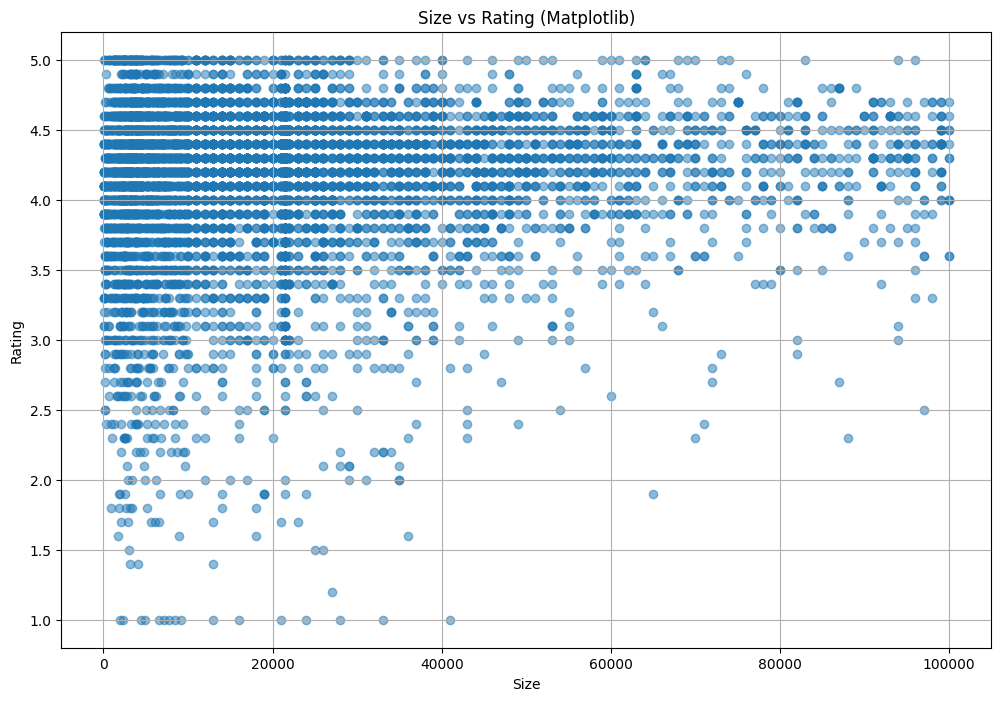

In [ ]:
###Size vs Rating

##Plot a scatter-plot in the matplotlib way between Size and Rating

import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8)) # Increased figure size
plt.scatter(inp1['Size'], inp1['Rating'], alpha=0.5)
plt.xlabel('Size')
plt.ylabel('Rating')
plt.title('Size vs Rating (Matplotlib)')
plt.grid(True)
plt.show()

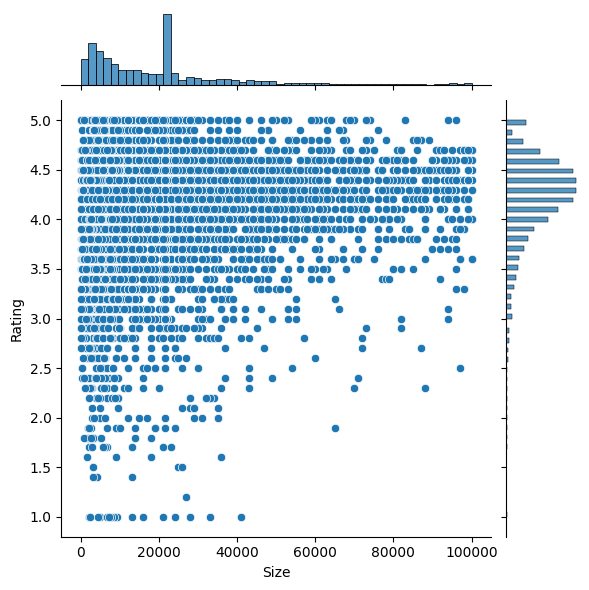

In [ ]:
### Plot the same thing now using a jointplot
sns.jointplot(data=inp1, x='Size', y='Rating')

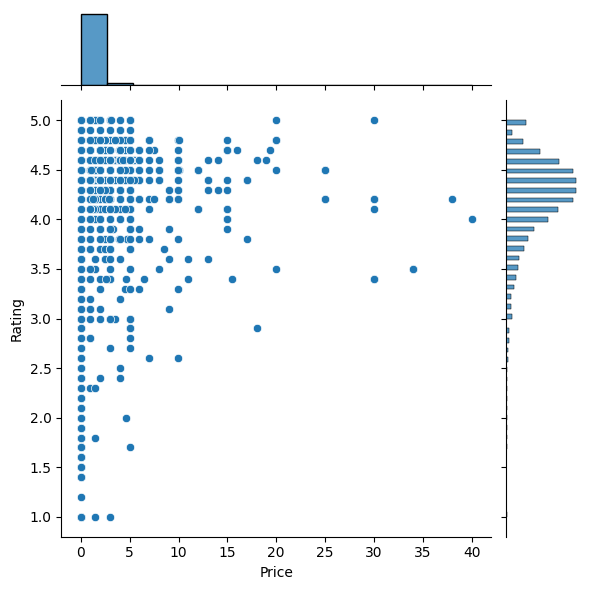

In [ ]:
## Plot a jointplot for Price and Rating
sns.jointplot(data=inp1, x='Price', y='Rating')

**Reg Plots**

- These are an extension to the jointplots, where a regression line is added to the view

In [ ]:
##Plot a reg plot for Price and Rating and observe the trend



In [ ]:
## Question - Plot a reg plot for Price and Rating again for only the paid apps.


**Pair Plots**

 - When you have several numeric variables, making multiple scatter plots becomes rather tedious. Therefore, a pair plot visualisation is preferred where all the scatter plots are in a single view in the form of a matrix
 - For the non-diagonal views, it plots a **scatter plot** between 2 numeric variables
 - For the diagonal views, it plots a **histogram**

Pair Plots help in identifying the trends between a target variable and the predictor variables pretty quickly. For example, say you want to predict how your company’s profits are affected by three different factors. In order to choose which you created a pair plot containing profits and the three different factors as the variables. Here are the scatterplots of profits vs the three variables that you obtained from the pair plot.

![Pairplots](images\pairplots2.png)

It is clearly visible that the left-most factor is the most prominently related to the profits, given how linearly scattered the points are and how randomly scattered the rest two factors are.

You'll be using **sns.pairplot()** for this visualisation. Check out its official documentation:https://seaborn.pydata.org/generated/seaborn.pairplot.html

In [ ]:
## Create a pair plot for Reviews, Size, Price and Rating



**Bar Charts Revisited**

- Here, you'll be using bar charts once again, this time using the **sns.barplot()** function. Check out its official documentation:https://seaborn.pydata.org/generated/seaborn.barplot.html
- You can modify the **estimator** parameter to change the aggregation value of your barplot

In [ ]:
##Plot a bar plot of Content Rating vs Average Rating


In [ ]:
##Plot the bar plot again with Median Rating


In [ ]:
##Plot the above bar plot using the estimator parameter



In [ ]:
##Plot the bar plot with only the 5th percentile of Ratings


In [ ]:
##Question - Plot the bar plot with the minimum Rating


__Box Plots Revisited__

- Apart from outlier analysis, box plots are great at comparing the spread and analysing a numerical variable across several categories
- Here you'll be using **sns.boxplot()** function to plot the visualisation. Check out its documentation: https://seaborn.pydata.org/generated/seaborn.boxplot.html




In [ ]:
##Plot a box plot of Rating vs Content Rating


In [ ]:
##Question - Plot a box plot for the Rating column only


In [ ]:
##Question - Plot a box plot of Ratings across the 4 most popular Genres


#### Heat Maps

Heat mapsutilise the concept of using colours and colour intensities to visualise a range of values. You must have seen heat maps in cricket or football broadcasts on television to denote the players’ areas of strength and weakness.

![HeatMap](images\heatmap1.png)

- In python, you can create a heat map whenever you have a rectangular grid or table of numbers analysing any two features

![heatmap2](images\heatmap2.png)

- You'll be using **sns.heatmap()** to plot the visualisation. Checkout its official documentation :https://seaborn.pydata.org/generated/seaborn.heatmap.html

In [ ]:
##Ratings vs Size vs Content Rating

##Prepare buckets for the Size column using pd.qcut



In [ ]:
##Create a pivot table for Size_buckets and Content Rating with values set to Rating


In [ ]:
##Change the aggregation to median


In [ ]:
##Change the aggregation to 20th percentile


In [ ]:
##Store the pivot table in a separate variable


In [ ]:
##Plot a heat map


In [ ]:
##Apply customisations


In [ ]:
##Question - Replace Content Rating with Review_buckets in the above heat map
##Keep the aggregation at minimum value for Rating


### Session 3: Additional Visualisations

#### Line Plots

- A line plot tries to observe trends using time dependent data.
-  For this part, you'll be using **pd.to_datetime()** function. Check out its documentation:https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.to_datetime.html


In [ ]:
## Extract the month from the Last Updated Date



In [ ]:
## Find the average Rating across all the months



In [ ]:
## Plot a line graph



#### Stacked Bar Charts

- A stacked bar chart breaks down each bar of the bar chart on the basis of a different category
- For example, for the Campaign Response bar chart you saw earlier, the stacked bar chart is also showing the Gender bifurcation as well

![Stacked](images\stacked.png)

In [ ]:
## Create a pivot table for Content Rating and updated Month with the values set to Installs


In [ ]:
##Store the table in a separate variable


In [ ]:
##Plot the stacked bar chart.


In [ ]:
##Plot the stacked bar chart again wrt to the proportions.



#### Plotly

Plotly is a Python library used for creating interactive visual charts. You can take a look at how you can use it to create aesthetic looking plots with a lot of user-friendly functionalities like hover, zoom, etc.

Check out this link for installation and documentation:https://plot.ly/python/getting-started/

In [ ]:
#Install plotly


In [ ]:
#Take the table you want to plot in a separate variable


In [ ]:
#Import the plotly libraries


In [ ]:
#Prepare the plot


analysis
1. import and setup
2. Data Cleanup and Type fixing (normalization and scaling)
3. Exploratory Data Analysis (univariate)
4. EDA-Bivariate and Multivariate
5. Statistical test t-test
6. Chi Square test
7. Pearson correlation
8. Spearman Correlation
9. One way Anova
10. Two way Anova
11. Interpretation Table (summary of you analytics)

In [ ]:
from scipy import stats
from statsmodels.stats.anova import anova_lm
from statsmodels.formula.api import ols

In [ ]:
#bivariate analysis
#checking relationship between two variables
# Rating vs size, Rating vs Prize, Rating vs installs, Category vs Rating, Free vs Paid Rating

Free vs Paid Apps

/tmp/ipykernel_2424/4276172511.py:1: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




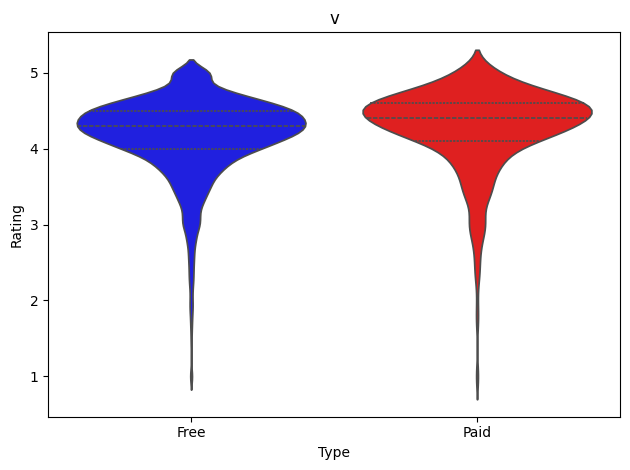

In [ ]:
sns.violinplot(inp1, x = 'Type', y = 'Rating',

               inner = 'quart',
               palette = {'Free' : 'blue', 'Paid' : 'red'})
plt.title('v')
plt.tight_layout(); plt.show()
# split = True only works with 2-level hue
# inner options: "box", "point", "stick"

In [ ]:
import plotly.express as px

fig = px.violin(data_frame=inp1,
                x='Type',
                y='Rating',
                color='Type',
                color_discrete_map={'Free': 'blue', 'Paid': 'red'},
                title='Rating Distribution by App Type with Outliers')

fig.show()

In [ ]:
import plotly.express as px
fig = px.violin(data_frame = inp1, x = 'Type', y = 'Category', title = 'Rating Distribution by App Type and Genre')
fig.show()

In [ ]:
import plotly.graph_objects as go
import pandas as pd

# Calculate the average rating for each category and app type
average_ratings = inp1.groupby(['Category', 'Type'])['Rating'].mean().reset_index()

# Pivot the table to have Free and Paid ratings as separate columns
pivot_ratings = average_ratings.pivot(index='Category', columns='Type', values='Rating').reset_index()
pivot_ratings.columns.name = None # Remove the column name 'Type' for cleaner plotting

# Calculate overall average rating for sorting
pivot_ratings['Overall_Average_Rating'] = pivot_ratings[['Free', 'Paid']].mean(axis=1)

# Sort categories by overall average rating
pivot_ratings_sorted = pivot_ratings.sort_values(by='Overall_Average_Rating', ascending=True)

fig = go.Figure()

# Add lines connecting Free and Paid ratings for each category
for index, row in pivot_ratings_sorted.iterrows():
    fig.add_trace(go.Scatter(
        x=[row['Free'], row['Paid']],
        y=[row['Category'], row['Category']],
        mode='lines',
        showlegend=False,
        line=dict(color='gray', width=1),
        hoverinfo='none'
    ))

# Add scatter points for Free apps
fig.add_trace(go.Scatter(
    x=pivot_ratings_sorted['Free'],
    y=pivot_ratings_sorted['Category'],
    mode='markers',
    name='Free',
    marker=dict(color='blue', size=10),
    hovertemplate='<b>Category</b>: %{y}<br><b>Free App Rating</b>: %{x:.2f}<extra></extra>'
))

# Add scatter points for Paid apps
fig.add_trace(go.Scatter(
    x=pivot_ratings_sorted['Paid'],
    y=pivot_ratings_sorted['Category'],
    mode='markers',
    name='Paid',
    marker=dict(color='red', size=10),
    hovertemplate='<b>Category</b>: %{y}<br><b>Paid App Rating</b>: %{x:.2f}<extra></extra>'
))

# Update layout
fig.update_layout(
    title='Average Rating Comparison: Free vs Paid Apps by Category (Dumbbell Plot)',
    xaxis_title='Average Rating',
    yaxis_title='Category',
    hovermode='closest',
    height=800, # Adjust height for better readability of categories
    margin=dict(l=100, r=20, t=60, b=20),
    yaxis=dict(categoryorder='array', categoryarray=pivot_ratings_sorted['Category'])
)

fig.show()

In [ ]:
# Size vs Rating scatterplot
import plotly.express as px
fig = px.scatter(inp1, x = 'Size', y = 'Rating', color = 'Type', title = 'Size vs Rating by Type', log_x=True)
fig.show()

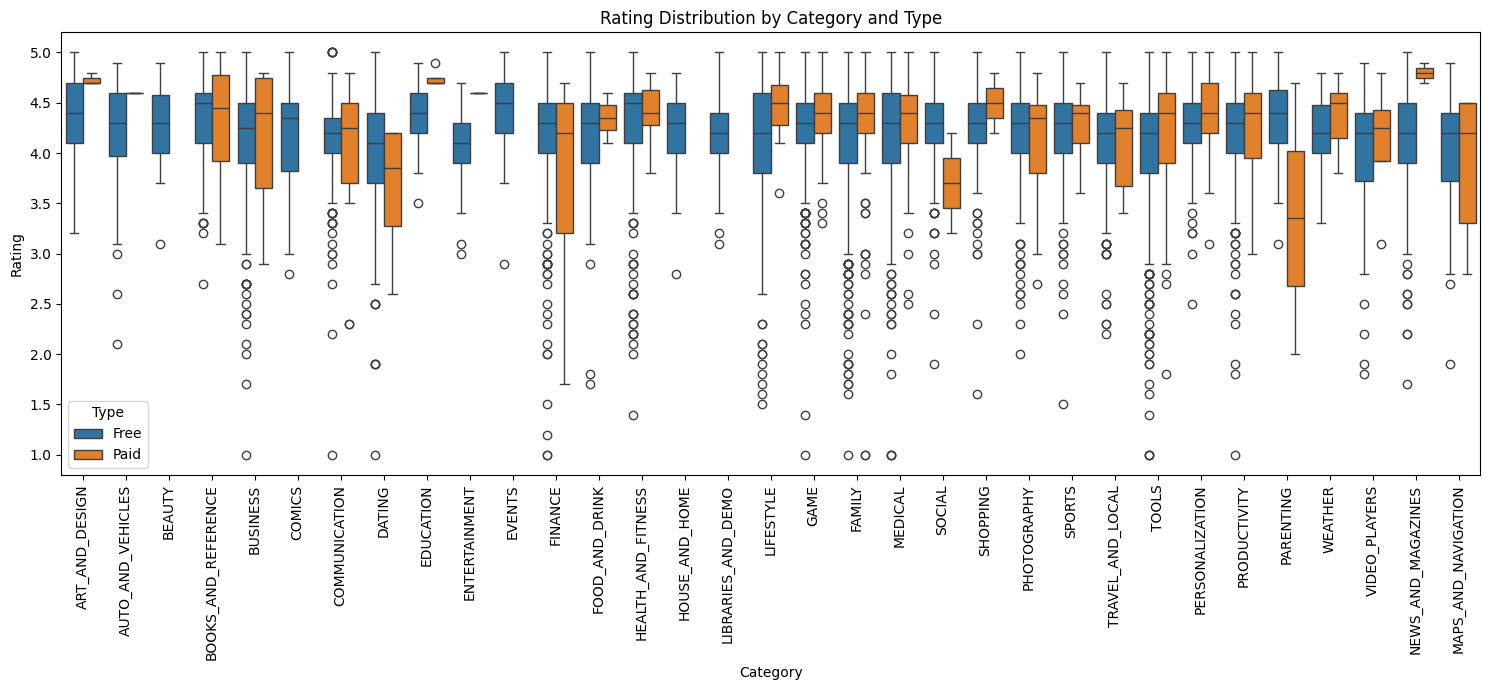

In [ ]:
# Category vs Rating boxplot
plt.figure(figsize=(15, 7))
sns.boxplot(inp1, x = 'Category', y = 'Rating', hue = 'Type')
plt.xticks(rotation=90)
plt.title('Rating Distribution by Category and Type')
plt.xlabel('Category')
plt.ylabel('Rating')
plt.tight_layout();
plt.show()

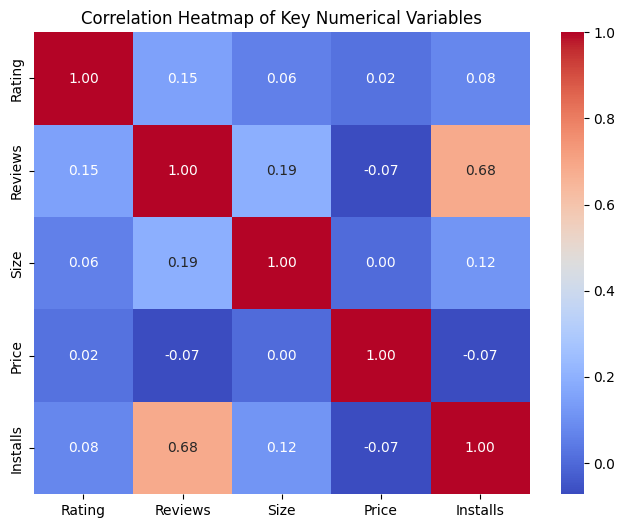

In [ ]:
# Corelation Heatmap
selected_cols = ['Rating', 'Reviews', 'Size', 'Price', 'Installs']
correlation_matrix = inp1[selected_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Key Numerical Variables')
plt.show()

In [ ]:
# Installs vs Rating Scatterplot
import plotly.express as px
fig = px.scatter(inp1, x = 'Installs', y = 'Rating', title = 'Installs vs Rating', log_x=True)
fig.show()

#T-test
- checks whether the means of two groups are statistically different from each other

- this is also called as two-sample t-test called as welch's test also

- Ho(null hypothesis) -> mean rating of free apps = mean rating of paid apps

- h1(alternative hypothesis) -> mean rating of free apps != mean rating of paid apps

- p = 0.05

- decision rule reject Ho if p-value < alpha

#p-value significance
1. if p > 0.05 Hypothesis is weak
2. if p < 0.05 Hypothesis is significant
- if p < 0.01 Hypothesis is strong
- if p < 0.001 Hypothsis is very strong

In [ ]:
free_rating = inp1[inp1['Type'] == 'Free']['Rating']
paid_rating = inp1[inp1['Type'] == 'Paid']['Rating']


In [ ]:
print(len(free_rating))
print(len(paid_rating))

7948
625


In [ ]:
mean_free = free_rating.mean().round(2)
mean_paid = paid_rating.mean().round(2)
print(mean_free,'\n',mean_paid)

4.16 
 4.27


In [ ]:
std_free = round(free_rating.std(), 2)
std_paid = round(paid_rating.std(), 2)
print(std_free)
print(std_paid)

0.53
0.55


In [ ]:
t_stat, p_stat = stats.ttest_ind(free_rating, paid_rating, equal_var = False)
print(f't-statistic: {t_stat:.4f}')
print(f'p-value: {p_stat:.6f}')

t-statistic: -4.7093
p-value: 0.000003


- since the p-value is very smll it is a strong evidence that mean rating of free and paid apps are different.

- since the p-value is 4.7, it means the two of the means are 4.7 standard error apart.

- 2 standard aparts significant
- 3 stringy significant
- 4 and above very strongly significant


inference is that paid apps have higher rating than free apps, the reasons could be that paid apps have better support and stable versions.

# Chi-Square Test
Test of Independence
- check whether the two categorival variables are associated to each other or not

1. Ho (Null Hypothesis) -> App Type & Content Rating are independent.
2. H1 (Alternative Hypothesis) -> They are associated.
 - x^2 = summation (observed - suspected)^2/expected

  χ² = Σ (O — E)² / E

- df = (rows-1) * (columns-1)


In [ ]:
# How to find the expected values?
inp1['Content Rating'].value_counts()

,count
Content Rating,
Everyone,6902
Teen,918
Mature 17+,417
Everyone 10+,336


In [ ]:
inp1['Type'].value_counts()

,count
Type,
Free,7948
Paid,625


In [ ]:
inp1.shape

(8573, 13)

In [ ]:
print(7948/8573)
print(6902/8573)
print((7948/8573) * (6902/8573))

0.927096698938528
0.8050857342820483
0.7463923266153879


In [ ]:
contingency = pd.crosstab(inp1['Type'], inp1['Content Rating'])

In [ ]:
# chi-square test -stats
stats.chi2_contingency(contingency)

Chi2ContingencyResult(statistic=np.float64(18.611507615208577), pvalue=np.float64(0.0003289162018618248), dof=3, expected_freq=array([[6398.82141607,  311.50449084,  386.59932346,  851.07476963],
       [ 503.17858393,   24.49550916,   30.40067654,   66.92523037]]))

In [ ]:
from scipy import stats
from statsmodels.stats.anova import anova_lm
from statsmodels.formula.api import ols

In [ ]:
from scipy import stats
import numpy as np

# Given data for Group 1 (restricted diet) and Group 2 (unrestricted diet)
x1, s1, n1 = 700, 21, 12
x2, s2, n2 = 668, 30, 6

# Hypotheses: Ho: u1 = u2, Ha: u1 > u2 (one-tailed test)

# Calculate Welch's t-statistic for unequal variances
numerator = x1 - x2
denominator_sq = (s1**2 / n1) + (s2**2 / n2)
t_statistic = numerator / np.sqrt(denominator_sq)

# Calculate degrees of freedom using Welch-Satterthwaite equation
v1_term = (s1**2 / n1)
v2_term = (s2**2 / n2)
df = (v1_term + v2_term)**2 / ((v1_term**2 / (n1 - 1)) + (v2_term**2 / (n2 - 1)))

# Calculate one-tailed p-value (right-tailed test)
p_value = stats.t.sf(t_statistic, df)

alpha = 0.05

print(f"T-statistic: {t_statistic:.4f}")
print(f"Degrees of Freedom: {df:.2f}")
print(f"P-value: {p_value:.4f}")

if p_value < alpha:
    print(f"Since p-value ({p_value:.4f}) < alpha ({alpha}), we reject the null hypothesis.")
    print("Conclusion: A restricted calorie diet does increase the lifespan of rats.")
else:
    print(f"Since p-value ({p_value:.4f}) >= alpha ({alpha}), we fail to reject the null hypothesis.")
    print("Conclusion: There is no sufficient evidence to conclude that a restricted calorie diet increases the lifespan of rats.")

T-statistic: 2.3416
Degrees of Freedom: 7.54
P-value: 0.0246
Since p-value (0.0246) < alpha (0.05), we reject the null hypothesis.
Conclusion: A restricted calorie diet does increase the lifespan of rats.


In [ ]:
from scipy import stats
import numpy as np

# Given data
# Group 1 (restricted calorie diet)
x1 = 700  # average lifespan
s1 = 21   # standard deviation
n1 = 12   # sample size

# Group 2 (unrestricted access to food)
x2 = 668  # average lifespan
s2 = 30   # standard deviation
n2 = 6    # sample size

# Hypotheses
# Ho: u1 = u2 (mean lifespan of restricted diet = mean lifespan of unrestricted diet)
# Ha: u1 > u2 (restricted calorie diet increases lifespan) - One-tailed test

# Calculate the t-statistic (Welch's t-test for unequal variances)
# The formula given in the cell is correct for Welch's t-test
numerator = x1 - x2
denominator = np.sqrt((s1**2 / n1) + (s2**2 / n2))
t_statistic = numerator / denominator

# Calculate degrees of freedom using Welch-Satterthwaite equation
# df = ((s1^2/n1 + s2^2/n2)^2) / (((s1^2/n1)^2 / (n1-1)) + ((s2^2/n2)^2 / (n2-1)))
v1 = s1**2 / n1
v2 = s2**2 / n2
df = (v1 + v2)**2 / ((v1**2 / (n1 - 1)) + (v2**2 / (n2 - 1)))

# Calculate the p-value for a one-tailed test (Ha: u1 > u2)
p_value = stats.t.sf(t_statistic, df) # sf is the survival function (1 - cdf) for right-tailed test

alpha = 0.05

print(f"T-statistic: {t_statistic:.4f}")
print(f"Degrees of Freedom: {df:.2f}")
print(f"P-value: {p_value:.4f}")

if p_value < alpha:
    print(f"Since p-value ({p_value:.4f}) < alpha ({alpha}), we reject the null hypothesis.")
    print("Conclusion: A restricted calorie diet does increase the lifespan of rats.")
else:
    print(f"Since p-value ({p_value:.4f}) >= alpha ({alpha}), we fail to reject the null hypothesis.")
    print("Conclusion: There is no sufficient evidence to conclude that a restricted calorie diet increases the lifespan of rats.")

T-statistic: 2.3416
Degrees of Freedom: 7.54
P-value: 0.0246
Since p-value (0.0246) < alpha (0.05), we reject the null hypothesis.
Conclusion: A restricted calorie diet does increase the lifespan of rats.


In [ ]:
d_f = 16
t_test = 2.342
p_test = stats.t.sf(t_test, d_f)
alph = 0.05

print(f"T-statistic: {t_test:.4f}")
print(f"Degrees of Freedom: {d_f:.2f}")
print(f"P-value: {p_test:.4f}")

if p_test < alph:
    print(f"Since p-value ({p_test:.4f}) < alpha ({alph}), we reject the null hypothesis.")
    print("Conclusion: A restricted calorie diet does increase the lifespan of rats.")
else:
    print(f"Since p-value ({p_test:.4f}) >= alpha ({alph}), we fail to reject the null hypothesis.")
    print("Conclusion: There is no sufficient evidence to conclude that a restricted calorie diet increases the lifespan of rats.")

T-statistic: 2.3420
Degrees of Freedom: 16.00
P-value: 0.0162
Since p-value (0.0162) < alpha (0.05), we reject the null hypothesis.
Conclusion: A restricted calorie diet does increase the lifespan of rats.
